<a href="https://colab.research.google.com/github/raditya12/periapical-lesion-classification-pcvk-/blob/master/01b_Segmentasi_ROI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentasi & ROI
**Proyek:** Klasifikasi Lesion Periapikal (PCVK)

**Jobdesk:** Otsu Thresholding, Morphological Operations, penentuan area gigi, dan ROI di sekitar apex.

**Isi notebook (4 bagian):** setup → prasyarat (dari Destian) → segmentasi & ROI → uji coba + bukti.


## 1. Setup — Mount Drive & Import

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
# dataset sudah tersimpan di Drive (tidak perlu ekstrak ulang)
DATA = '/content/drive/MyDrive/Lesion_Dataset'
print(sorted(os.listdir(DATA)))

# ------------------------------------------------------------------
# Mount Google Drive

!pip -q install scikit-image

import glob, os, re, time, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import regionprops

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)
import pandas as pd

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print('Setup selesai.')


Mounted at /content/drive
['LICENSE', 'README.md', 'healthy_root', 'lesion']
Setup selesai.


## 2. Prasyarat — daftar file & fungsi praproses

In [2]:
# daftar file + label + ID pasien (dari tahap EDA)
import glob, re
DATA = '/content/drive/MyDrive/Lesion_Dataset'
files, labels, pids = [], [], []
for kelas, lab in [('lesion', 1), ('healthy_root', 0)]:
    for f in sorted(glob.glob(f'{DATA}/{kelas}/*.TIF')):
        files.append(f); labels.append(lab)
        pids.append(re.match(r'P\d{6}', os.path.basename(f)).group(0))
labels = np.array(labels); pids = np.array(pids)
print(f'{len(files)} citra | {len(set(pids))} pasien')

# ------------------------------------------------------------------
# Daftar file, label, dan ID pasien

RESIZE_W, RESIZE_H = 512, 320

def preprocess(path, use_clahe=True):
    """(jobdesk: Dataset dan Preprocessing) grayscale -> resize 512x320
    -> CLAHE (opsional, clipLimit=2.0 tile 8x8) -> Gaussian blur 5x5."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (RESIZE_W, RESIZE_H), interpolation=cv2.INTER_AREA)
    if use_clahe:
        img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)
    return cv2.GaussianBlur(img, (5, 5), sigmaX=1.0)


2285 citra | 1295 pasien


## 3. Segmentasi & ROI

Enam langkah: buang tepi → Otsu thresholding → closing → opening → area gigi & apex → crop ROI.

In [3]:
ROI_HALF_W, ROI_TOP, ROI_BOT = 110, 60, 140   # jendela crop di sekitar apex

def segment_roi(img):
    """Segmentasi & ROI (jobdesk: Segmentasi dan ROI).
    1. Buang tepi gambar (background gelap / rongga non-anatomi).
    2. Thresholding OTSU (cv2.THRESH_OTSU) -> mask gigi (terang) vs background (gelap).
    3. Morphological Operations: closing (satukan bagian gigi terpecah),
       opening (buang titik noise).
    4. Penentuan area gigi: connected component >= 3% region utama.
    5. Penentuan apex: titik terbawah tiap region gigi.
    6. ROI: crop jendela di sekitar apex (x +/- 110 px, y dari -60 s.d. +140).
    Fallback: [citra penuh] bila tidak ada apex terdeteksi (pipeline tidak pernah gagal).
    Return: (daftar_crop, dict_debug) - debug berisi mask & apex untuk visualisasi."""
    H, W = img.shape
    oy, ox = int(H * 0.06), int(W * 0.08)
    inner = img[oy:H - oy, ox:W - ox]

    # --- Otsu Thresholding ---
    otsu_thr, tooth = cv2.threshold(inner.astype(np.uint8), 0, 255,
                                    cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tooth = tooth > 0

    # --- Morphological Operations ---
    k = np.ones((5, 5), np.uint8)
    tooth = ndimage.binary_closing(tooth, structure=k, iterations=6)
    tooth = ndimage.binary_opening(tooth, structure=k, iterations=3)

    # --- Penentuan area gigi & apex ---
    lab, n = ndimage.label(tooth)
    crops, apexes = [], []
    if n > 0:
        sizes = ndimage.sum(tooth, lab, range(1, n + 1))
        main = sizes.max()
        for kk in range(1, n + 1):
            if sizes[kk - 1] < 0.03 * main:
                continue
            ys, xs = np.where(lab == kk)
            if len(ys) < 100:
                continue
            i_b = np.argmax(ys)              # apex = titik terbawah region
            ax, ay = xs[i_b] + ox, ys[i_b] + oy
            apexes.append((ax, ay))
            x0, x1 = max(0, ax - ROI_HALF_W), min(W, ax + ROI_HALF_W)
            y0, y1 = max(0, ay - ROI_TOP), min(H, ay + ROI_BOT)
            crops.append(img[y0:y1, x0:x1])

    if not crops:                        # fallback whole-image
        crops = [img]
    debug = {'mask': tooth, 'apexes': apexes, 'otsu_thr': otsu_thr,
             'offset': (oy, ox), 'fallback': len(crops) == 1 and not apexes}
    return crops, debug


## 4. Uji coba dan bukti kerja

1. **Uji cepat** — 5 citra, cek jumlah apex dan ukuran crop.
2. **Visualisasi 4 tahap** — citra → mask → apex+ROI → hasil crop.
3. **Uji massal** — statistik keberhasilan pada 200 citra acak (angka untuk laporan).


P000155_007.TIF      | 1 apex     | thr=140 | crop: 162x92
P000156_004.TIF      | 1 apex     | thr=107 | crop: 186x92
P000156_009.TIF      | 2 apex     | thr=119 | crop: 202x113, 220x92
P000165_001.TIF      | 1 apex     | thr=117 | crop: 162x92
P000165_011.TIF      | 2 apex     | thr=116 | crop: 220x92, 162x92


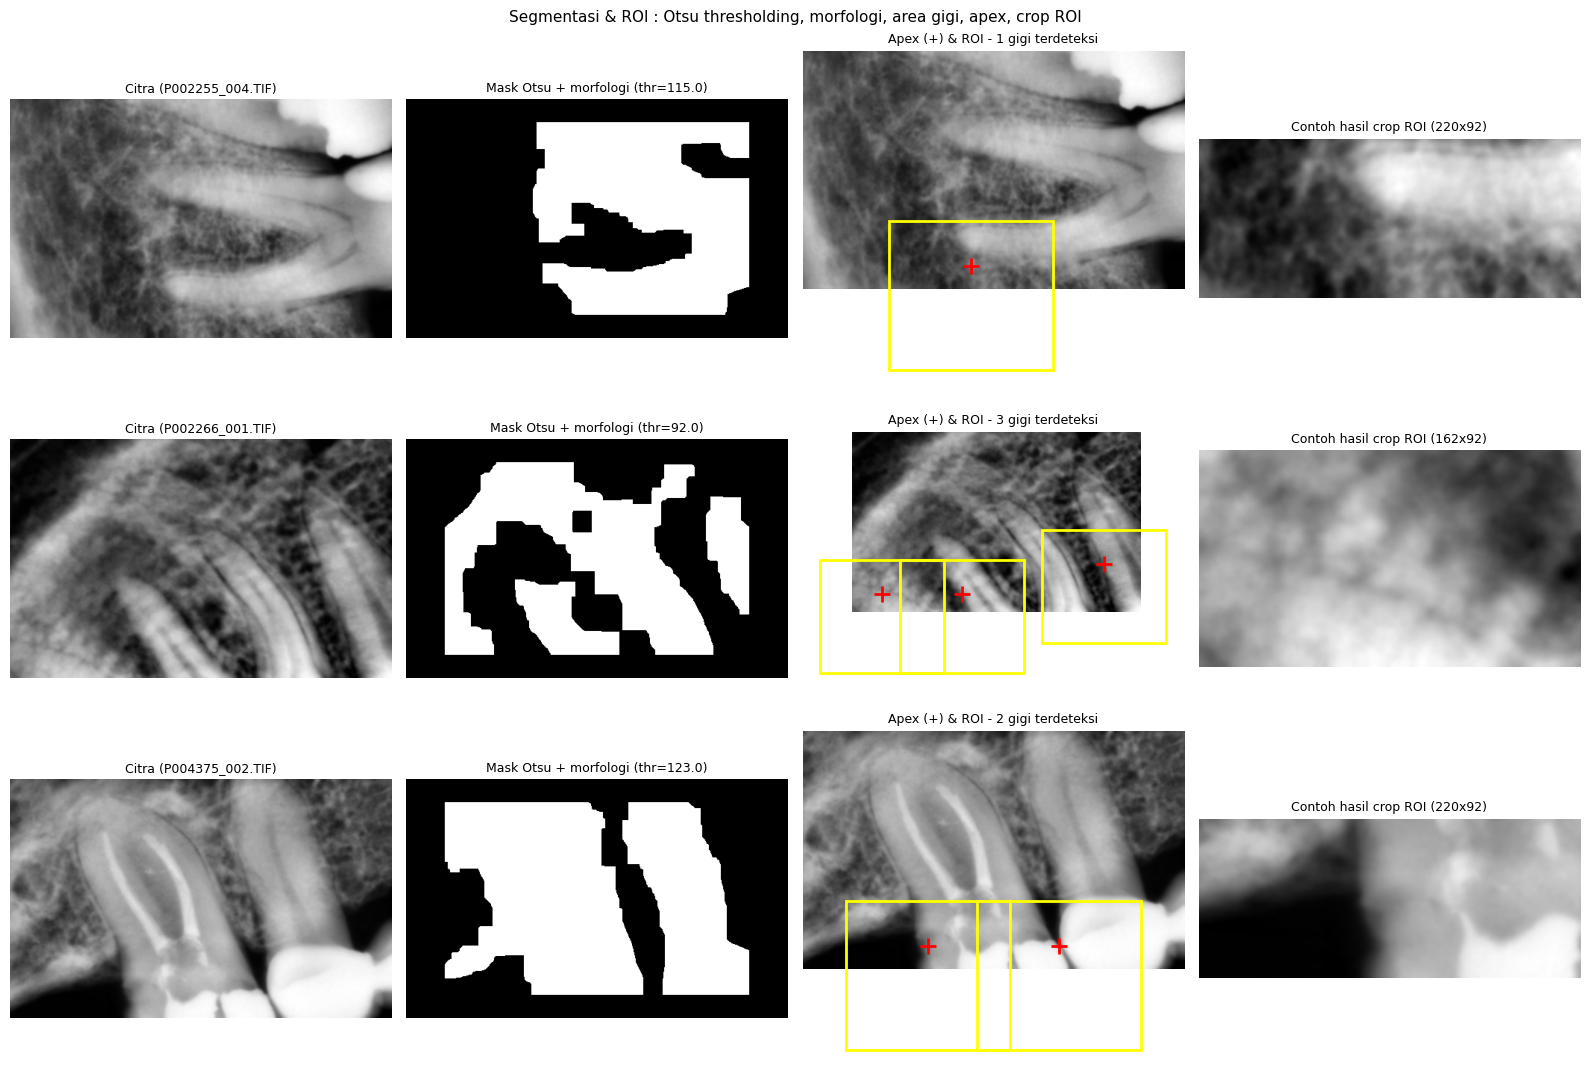

Statistik contoh: {'ok': 3, 'fallback': 0, 'multi': 2} - fallback = tidak ada apex terdeteksi, pakai whole-image
Citra diuji            : 200
Apex terdeteksi        : 200 (100%)
Fallback whole-image   : 0 (0%)
Multi-gigi (>=2 apex)  : 76 (38%)
Cakupan mask (median)  : 59.4% area citra

Catatan: mask yang menyatu terlalu besar (>60% area) berisiko apex bukan anatomi.
Tercatat sebagai keterbatasan + rencana perbaikan (filter apex tepi, batas cakupan mask).


In [5]:
# tes cepat segmentasi pada 5 citra
for f in files[:5]:
    img = preprocess(f, use_clahe=True)
    crops, dbg = segment_roi(img)
    ukuran = [f'{c.shape[1]}x{c.shape[0]}' for c in crops]
    status = 'FALLBACK' if dbg['fallback'] else f"{len(dbg['apexes'])} apex"
    print(f"{os.path.basename(f):20s} | {status:10s} | thr={dbg['otsu_thr']:.0f} | crop: {', '.join(ukuran)}")

# ------------------------------------------------------------------
# Uji cepat 5 citra

# VISUALISASI KERJA SEGMENTASI & ROI (bukti jobdesk: Otsu, morfologi, area gigi, apex, crop)
# tampilkan mask Otsu + apex + kotak ROI untuk 3 citra lesion & 3 healthy acak
import random
random.seed(7)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
stats = {'ok': 0, 'fallback': 0, 'multi': 0}
for row in range(3):
    f = random.choice(files)
    img = preprocess(f, use_clahe=True)
    crops, dbg = segment_roi(img)
    stats['ok' if not dbg['fallback'] else 'fallback'] += 1
    stats['multi'] += int(len(dbg['apexes']) >= 2)
    oy, ox = dbg['offset']

    ax = axes[row][0]
    ax.imshow(img, cmap='gray'); ax.set_title(f'Citra ({os.path.basename(f)[:16]})', fontsize=9); ax.axis('off')

    ax = axes[row][1]
    mask_full = np.zeros_like(img, dtype=np.uint8)
    mask_full[oy:oy + dbg['mask'].shape[0], ox:ox + dbg['mask'].shape[1]] = dbg['mask'].astype(np.uint8) * 255
    ax.imshow(mask_full, cmap='gray')
    ax.set_title(f"Mask Otsu + morfologi (thr={dbg['otsu_thr']})", fontsize=9); ax.axis('off')

    ax = axes[row][2]
    ax.imshow(img, cmap='gray')
    for (ax_p, ay_p) in dbg['apexes']:
        ax.plot(ax_p, ay_p, 'r+', markersize=12, markeredgewidth=2)
        ax.add_patch(plt.Rectangle((ax_p - ROI_HALF_W, ay_p - ROI_TOP),
                                   2 * ROI_HALF_W, ROI_TOP + ROI_BOT,
                                   fill=False, edgecolor='yellow', linewidth=2))
    ax.set_title(f"Apex (+) & ROI - {len(dbg['apexes'])} gigi terdeteksi", fontsize=9); ax.axis('off')

    ax = axes[row][3]
    if len(crops) > 0 and not dbg['fallback']:
        ax.imshow(crops[0], cmap='gray')
        ax.set_title(f'Contoh hasil crop ROI ({crops[0].shape[1]}x{crops[0].shape[0]})', fontsize=9)
    else:
        ax.imshow(img, cmap='gray'); ax.set_title('FALLBACK whole-image', fontsize=9)
    ax.axis('off')

plt.suptitle('Segmentasi & ROI : Otsu thresholding, morfologi, area gigi, apex, crop ROI', fontsize=11)
plt.tight_layout(); plt.show()
print('Statistik contoh:', stats, '- fallback = tidak ada apex terdeteksi, pakai whole-image')

# ------------------------------------------------------------------
# Visualisasi 4 tahap (bukti kerja)

# ===== UJI MASSAL: statistik segmentasi pada 200 citra acak =====
import random
random.seed(42)
N = 200
sample_files = random.sample(files, N)

ok, fallback, multi, coverages = 0, 0, 0, []
for f in sample_files:
    img = preprocess(f, use_clahe=True)
    crops, dbg = segment_roi(img)
    if dbg['fallback']:
        fallback += 1
    else:
        ok += 1
        coverages.append(dbg['mask'].mean() * 100)
    if len(dbg['apexes']) >= 2:
        multi += 1

print(f'Citra diuji            : {N}')
print(f'Apex terdeteksi        : {ok} ({ok/N*100:.0f}%)')
print(f'Fallback whole-image   : {fallback} ({fallback/N*100:.0f}%)')
print(f'Multi-gigi (>=2 apex)  : {multi} ({multi/N*100:.0f}%)')
if coverages:
    print(f'Cakupan mask (median)  : {np.median(coverages):.1f}% area citra')
print()
print('Catatan: mask yang menyatu terlalu besar (>60% area) berisiko apex bukan anatomi.')
print('Tercatat sebagai keterbatasan + rencana perbaikan (filter apex tepi, batas cakupan mask).')


## Catatan bagian ini
- **Otsu** dipilih karena histogram radiografi bimodal (gigi terang vs latar gelap); ambang adaptif per citra.
- **Closing 6 iterasi → opening 3 iterasi**: rekatkan bagian gigi terpecah, lalu buang noise kecil.
- **Apex** = titik terbawah region gigi, karena lesi periapikal selalu menempel di ujung akar.
- **ROI** = crop jendela ±110 px horizontal, 60 px atas s.d. 140 px bawah dari apex.
- **Fallback** whole-image menjaga pipeline tidak pernah gagal.
